<a href="https://colab.research.google.com/github/Vivek3Tiwari/ml-network-intrusion-detection/blob/main/notebooks/NIDS_CICIDS2017.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import glob
files = glob.glob('/content/drive/MyDrive/NIDS/data/*.csv')
print(files)

[]


In [5]:
import os
print(os.listdir('/content/drive/MyDrive'))

['Colab Notebooks', 'NIDS data', 'Untitled folder', 'IMG20231204142919.jpg', 'IMG_2516.heic', 'Classroom', 'IMG_20241011_234152.jpg', 'Searching.gdoc', 'Yashiv', 'IMG_20250110_161046 (1).jpg', 'Resume', 'Book report.gslides', 'attendance ', 'Intership ', 'Screen Recording 2025-04-27 231058.mp4', 'Screenshot_2025-05-15-17-44-43-60_ec576d6a4b63b6521ff16f5575cc4da0.jpg', 'resume.pdf', 'KNN Model Testing', 'front page_copy.pdf', 'Ethical Network Sniffing Framework Design (1).gdoc', 'Ethical Network Sniffing Framework Design.gdoc', 'Book', 'Cybersecurity Research Topics Generation.gdoc', 'profilepicture (1).jpeg', 'profilepicture.jpeg', 'FHE Continuous Authentication Review (3).gdoc', 'FHE Continuous Authentication Review (2).gdoc', 'FHE Continuous Authentication Review (1).gdoc', 'FHE Continuous Authentication Review.gdoc', 'privacy research paper content', '12 Marksheet.pdf', 'Offer letter ', 'Review Paper Enhancement Request.gdoc', 'Vivek Tiwari Resume.pdf', 'Vivek Tiwari DII Forwarding 

In [9]:
import os
print(os.listdir('/content/drive/MyDrive/NIDS data'))


['Wednesday-workingHours.pcap_ISCX.csv', 'Monday-WorkingHours.pcap_ISCX.csv', 'Tuesday-WorkingHours.pcap_ISCX.csv']


In [10]:
import glob
files = glob.glob('/content/drive/MyDrive/NIDS data/*.csv')
print(files)

['/content/drive/MyDrive/NIDS data/Wednesday-workingHours.pcap_ISCX.csv', '/content/drive/MyDrive/NIDS data/Monday-WorkingHours.pcap_ISCX.csv', '/content/drive/MyDrive/NIDS data/Tuesday-WorkingHours.pcap_ISCX.csv']


In [11]:
import pandas as pd
df = pd.read_csv(files[0], encoding='latin1')
print(df.shape)
df.head()

(692703, 79)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,80,38308,1,1,6,6,6,6,6.000000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,389,479,11,5,172,326,79,0,15.636364,31.449238,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,88,1095,10,6,3150,3150,1575,0,315.000000,632.561635,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,389,15206,17,12,3452,6660,1313,0,203.058823,425.778474,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,88,1092,9,6,3150,3152,1575,0,350.000000,694.509719,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [12]:
import pandas as pd, glob, os

files = sorted(glob.glob('/content/drive/MyDrive/NIDS data/*.csv'))

dfs = []
for f in files:
    df = pd.read_csv(f, encoding='latin1', low_memory=False)
    df.columns = df.columns.str.strip()   # removes hidden spaces in column names
    print(os.path.basename(f), df.shape)
    dfs.append(df)

Monday-WorkingHours.pcap_ISCX.csv (529918, 79)
Tuesday-WorkingHours.pcap_ISCX.csv (445909, 79)
Wednesday-workingHours.pcap_ISCX.csv (692703, 79)


In [13]:
for f, df in zip(files, dfs):
    print(os.path.basename(f))
    print(df['Label'].value_counts())
    print()

Monday-WorkingHours.pcap_ISCX.csv
Label
BENIGN    529918
Name: count, dtype: int64

Tuesday-WorkingHours.pcap_ISCX.csv
Label
BENIGN         432074
FTP-Patator      7938
SSH-Patator      5897
Name: count, dtype: int64

Wednesday-workingHours.pcap_ISCX.csv
Label
BENIGN              440031
DoS Hulk            231073
DoS GoldenEye        10293
DoS slowloris         5796
DoS Slowhttptest      5499
Heartbleed              11
Name: count, dtype: int64



In [14]:
data = pd.concat(dfs, ignore_index=True)
print(data.shape)
data['Label'].value_counts()

(1668530, 79)


,count
Label,
BENIGN,1402023
DoS Hulk,231073
DoS GoldenEye,10293
FTP-Patator,7938
SSH-Patator,5897
DoS slowloris,5796
DoS Slowhttptest,5499
Heartbleed,11


In [15]:
import numpy as np

print('Before:', data.shape)
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna()
data = data.drop_duplicates()
data = data.reset_index(drop=True)
print('After:', data.shape)

Before: (1668530, 79)
After: (1526504, 79)


In [16]:
data['Label'] = data['Label'].str.strip()

label_map = {
    'BENIGN': 'BENIGN',
    'FTP-Patator': 'BruteForce',
    'SSH-Patator': 'BruteForce',
    'DoS Hulk': 'DoS',
    'DoS GoldenEye': 'DoS',
    'DoS slowloris': 'DoS',
    'DoS Slowhttptest': 'DoS',
}
data['Class'] = data['Label'].map(label_map)
data = data[data['Class'].notna()].reset_index(drop=True)   # drops Heartbleed (too few rows)
print(data['Class'].value_counts())

Class
BENIGN        1323598
DoS            193745
BruteForce       9150
Name: count, dtype: int64


In [17]:
data.to_parquet('/content/drive/MyDrive/NIDS data/clean_data.parquet', index=False)
print('Saved!')

Saved!


In [18]:
from sklearn.model_selection import train_test_split

X = data.drop(columns=['Label', 'Class']).astype('float32')   # the features
y = data['Class']                                            # the answer we want to predict

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(X_train.shape, X_test.shape)
print(y_train.value_counts())
print(y_test.value_counts())

(1221194, 78) (305299, 78)
Class
BENIGN        1058878
DoS            154996
BruteForce       7320
Name: count, dtype: int64
Class
BENIGN        264720
DoS            38749
BruteForce      1830
Name: count, dtype: int64


In [19]:
from sklearn.ensemble import RandomForestClassifier
import time

start = time.time()

rf = RandomForestClassifier(
    n_estimators=50,        # 50 trees (keeps it fast on free Colab)
    class_weight='balanced',  # pays extra attention to the tiny BruteForce class
    n_jobs=-1,              # uses all CPU cores
    random_state=42
)
rf.fit(X_train, y_train)

print('Training done in', round(time.time() - start), 'seconds')

Training done in 286 seconds


In [20]:
from sklearn.metrics import classification_report

y_pred = rf.predict(X_test)
print(classification_report(y_test, y_pred, digits=4))

              precision    recall  f1-score   support

      BENIGN     0.9996    0.9998    0.9997    264720
  BruteForce     1.0000    0.9995    0.9997      1830
         DoS     0.9987    0.9974    0.9981     38749

    accuracy                         0.9995    305299
   macro avg     0.9995    0.9989    0.9992    305299
weighted avg     0.9995    0.9995    0.9995    305299



In [21]:
import joblib
joblib.dump(rf, '/content/drive/MyDrive/NIDS data/rf_model.joblib')
print('Model saved!')

Model saved!


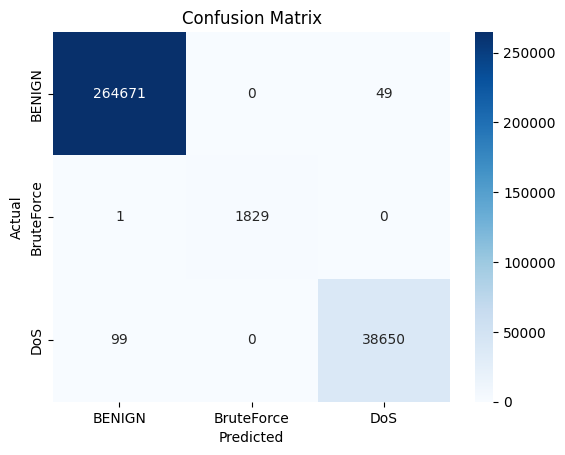

False alarms on normal traffic: 49 of 264720
False-positive rate: 0.0185 %


In [22]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

labels = ['BENIGN', 'BruteForce', 'DoS']
cm = confusion_matrix(y_test, y_pred, labels=labels)

sns.heatmap(cm, annot=True, fmt='d', xticklabels=labels, yticklabels=labels, cmap='Blues')
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion Matrix')
plt.savefig('/content/drive/MyDrive/NIDS data/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

benign_total = cm[0].sum()
false_alarms = benign_total - cm[0, 0]
print('False alarms on normal traffic:', false_alarms, 'of', benign_total)
print('False-positive rate:', round(false_alarms / benign_total * 100, 4), '%')

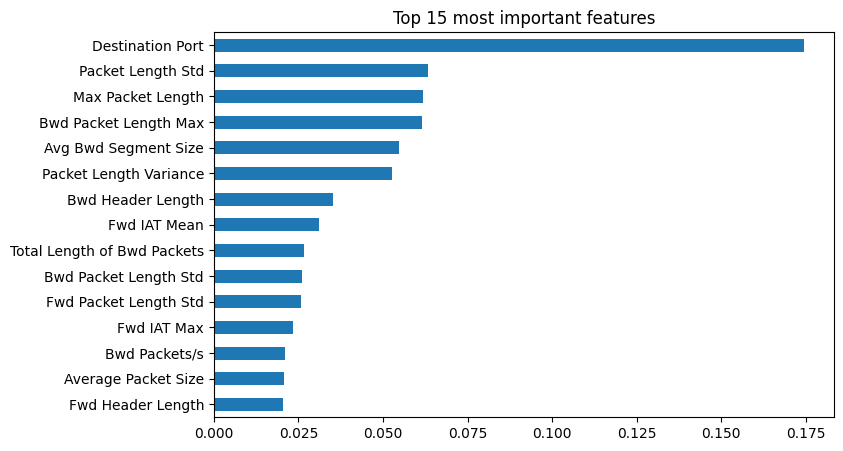

In [23]:
import pandas as pd

imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)
imp.plot.barh(figsize=(8, 5)).invert_yaxis()
plt.title('Top 15 most important features')
plt.savefig('/content/drive/MyDrive/NIDS data/feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

In [24]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)

xgb = XGBClassifier(n_estimators=100, n_jobs=-1, random_state=42)
xgb.fit(X_train, y_train_enc)

y_pred_xgb = le.inverse_transform(xgb.predict(X_test))
print(classification_report(y_test, y_pred_xgb, digits=4))

              precision    recall  f1-score   support

      BENIGN     1.0000    0.9998    0.9999    264720
  BruteForce     0.9989    0.9995    0.9992      1830
         DoS     0.9989    0.9997    0.9993     38749

    accuracy                         0.9998    305299
   macro avg     0.9993    0.9997    0.9995    305299
weighted avg     0.9998    0.9998    0.9998    305299



In [25]:
data['order'] = data.groupby('Class').cumcount()
data['size'] = data.groupby('Class')['order'].transform('max') + 1
is_train = data['order'] < 0.7 * data['size']   # first 70% = train, last 30% = test

X_all = data.drop(columns=['Label', 'Class', 'order', 'size']).astype('float32')
y_all = data['Class']

rf2 = RandomForestClassifier(n_estimators=50, class_weight='balanced', n_jobs=-1, random_state=42)
rf2.fit(X_all[is_train], y_all[is_train])

pred2 = rf2.predict(X_all[~is_train])
print(classification_report(y_all[~is_train], pred2, digits=4))

              precision    recall  f1-score   support

      BENIGN     0.9795    0.9998    0.9895    397079
  BruteForce     1.0000    0.9789    0.9893      2745
         DoS     0.9980    0.8579    0.9227     58123

    accuracy                         0.9816    457947
   macro avg     0.9925    0.9455    0.9672    457947
weighted avg     0.9820    0.9816    0.9810    457947



In [26]:
import json, os

OUT = '/content/drive/MyDrive/NIDS data/deploy'
os.makedirs(OUT, exist_ok=True)

xgb.save_model(f'{OUT}/xgb_model.json')
json.dump(list(X_train.columns), open(f'{OUT}/features.json', 'w'))
json.dump(list(le.classes_), open(f'{OUT}/classes.json', 'w'))

# Small sample file for the demo: 100 flows of each class
parts = [X_test[y_test == c].sample(100, random_state=1).assign(Actual=c)
         for c in ['BENIGN', 'DoS', 'BruteForce']]
sample = pd.concat(parts).sample(frac=1, random_state=1)
sample.to_csv(f'{OUT}/sample_flows.csv', index=False)

for fn in os.listdir(OUT):
    print(fn, round(os.path.getsize(f'{OUT}/{fn}') / 1e6, 2), 'MB')

xgb_model.json 0.68 MB
features.json 0.0 MB
classes.json 0.0 MB
sample_flows.csv 0.14 MB


In [27]:
app_code = '''import streamlit as st, pandas as pd, numpy as np, json
from xgboost import XGBClassifier

st.set_page_config(page_title="ML Network Intrusion Detection", layout="wide")
st.title("ML-based Network Intrusion Detection System")
st.caption("XGBoost classifier trained on CICIDS2017 (Mon-Wed). Upload network flow features to detect BENIGN, DoS and BruteForce traffic.")

@st.cache_resource
def load():
    m = XGBClassifier()
    m.load_model("xgb_model.json")
    return m, json.load(open("features.json")), json.load(open("classes.json"))

model, feats, classes = load()

use_sample = st.checkbox("Use the built-in sample file (300 flows)")
up = st.file_uploader("Or upload a CSV of flow features", type="csv")

df = None
if use_sample:
    df = pd.read_csv("sample_flows.csv")
elif up is not None:
    df = pd.read_csv(up, encoding="latin1", low_memory=False)

if df is not None:
    df.columns = df.columns.str.strip()
    missing = [c for c in feats if c not in df.columns]
    if missing:
        st.error("Missing columns: " + ", ".join(missing[:5]) + " ...")
        st.stop()

    X = df[feats].replace([np.inf, -np.inf], np.nan).fillna(0).astype("float32")
    proba = model.predict_proba(X)
    out = df.copy()
    out["Prediction"] = np.array(classes)[proba.argmax(1)]
    out["Confidence %"] = (proba.max(1) * 100).round(2)

    alerts = out[out["Prediction"] != "BENIGN"]
    c1, c2, c3 = st.columns(3)
    c1.metric("Flows analysed", len(out))
    c2.metric("Alerts", len(alerts))
    c3.metric("Benign", len(out) - len(alerts))

    st.subheader("Traffic breakdown")
    st.bar_chart(out["Prediction"].value_counts())

    st.subheader("Alerts")
    cols = ["Prediction", "Confidence %"] + feats[:6]
    st.dataframe(alerts[cols], use_container_width=True)

    st.download_button("Download full results", out.to_csv(index=False), "results.csv")
'''
open(f'{OUT}/app.py', 'w').write(app_code)

open(f'{OUT}/requirements.txt', 'w').write('streamlit\npandas\nnumpy\nxgboost\nscikit-learn\n')
print(os.listdir(OUT))

['xgb_model.json', 'features.json', 'classes.json', 'sample_flows.csv', 'app.py', 'requirements.txt']
